In [2]:
import pandas as pd

df = pd.read_csv(
    "/content/marketing_campaign.csv",
    sep="\t"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()
df.info()
df.columns.tolist()

Dataset loaded successfully.
Dataset shape: (2240, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-nul

['ID',
 'Year_Birth',
 'Education',
 'Marital_Status',
 'Income',
 'Kidhome',
 'Teenhome',
 'Dt_Customer',
 'Recency',
 'MntWines',
 'MntFruits',
 'MntMeatProducts',
 'MntFishProducts',
 'MntSweetProducts',
 'MntGoldProds',
 'NumDealsPurchases',
 'NumWebPurchases',
 'NumCatalogPurchases',
 'NumStorePurchases',
 'NumWebVisitsMonth',
 'AcceptedCmp3',
 'AcceptedCmp4',
 'AcceptedCmp5',
 'AcceptedCmp1',
 'AcceptedCmp2',
 'Complain',
 'Z_CostContact',
 'Z_Revenue',
 'Response']

In [6]:
#Check duplicates

print("\nMissing values by column:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:")
print(df.duplicated().sum())

#heck missing values
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

df.describe().T


Missing values by column:


,0
Income,24
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0



Duplicate rows:
0


,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [7]:
#Unusual data

print("Birth years before 1900:")
display(df[df["Year_Birth"] < 1900][["ID", "Year_Birth", "Income"]])

print("\nConstant columns:")
constant_columns = [
    column for column in df.columns
    if df[column].nunique(dropna=False) <= 1
]

print(constant_columns)

Birth years before 1900:


,ID,Year_Birth,Income
239,11004,1893,60182.0
339,1150,1899,83532.0



Constant columns:
['Z_CostContact', 'Z_Revenue']


In [8]:
# Data Cleaning

df_clean = df.copy()

# Remove unrealistic birth-year records
df_clean = df_clean[df_clean["Year_Birth"] >= 1900].copy()

# Fill missing income values with the median income
income_median = df_clean["Income"].median()
df_clean["Income"] = df_clean["Income"].fillna(income_median)

# Remove identifier and constant columns
df_clean = df_clean.drop(
    columns=["ID", "Z_CostContact", "Z_Revenue"]
)

print("Cleaned dataset shape:", df_clean.shape)
print("Remaining missing values:", df_clean.isnull().sum().sum())

Cleaned dataset shape: (2238, 26)
Remaining missing values: 0


In [10]:
#Feature Engineering

# Create customer age
df_clean["Age"] = 2014 - df_clean["Year_Birth"]

# Create total household dependents
df_clean["Children_Total"] = (
    df_clean["Kidhome"] + df_clean["Teenhome"]
)

# Create total spending across product categories
spending_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df_clean["Total_Spending"] = df_clean[spending_columns].sum(axis=1)

# Create total purchases across channels
purchase_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

df_clean["Total_Purchases"] = df_clean[purchase_columns].sum(axis=1)

# Create total accepted campaign offers
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5"
]

df_clean["Total_Campaign_Accepted"] = df_clean[campaign_columns].sum(axis=1)

print("Feature engineering completed.")
print("Updated dataset shape:", df_clean.shape)

display(
    df_clean[
        [
            "Age",
            "Children_Total",
            "Total_Spending",
            "Total_Purchases",
            "Total_Campaign_Accepted"
        ]
    ].head()
)


numerical_features = df_clean.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

Feature engineering completed.
Updated dataset shape: (2238, 31)


,Age,Children_Total,Total_Spending,Total_Purchases,Total_Campaign_Accepted
0,57,0,1617,22,0
1,60,2,27,4,0
2,49,0,776,20,0
3,30,1,53,6,0
4,33,1,422,14,0


Numerical features:
['Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response', 'Age', 'Children_Total', 'Total_Spending', 'Total_Purchases', 'Total_Campaign_Accepted']


In [12]:
#Clustering based on numeriacal features

clustering_features = [
    "Age",
    "Income",
    "Children_Total",
    "Recency",
    "Total_Spending",
    "Total_Purchases",
    "NumDealsPurchases",
    "NumWebVisitsMonth",
    "Total_Campaign_Accepted"
]

X = df_clean[clustering_features].copy()

print("Selected clustering features:")
print(clustering_features)

print("\nClustering data shape:", X.shape)

display(X.head())

print("Feature skewness:")
display(
    X.skew()
     .sort_values(ascending=False)
     .to_frame("skewness")
)

Selected clustering features:
['Age', 'Income', 'Children_Total', 'Recency', 'Total_Spending', 'Total_Purchases', 'NumDealsPurchases', 'NumWebVisitsMonth', 'Total_Campaign_Accepted']

Clustering data shape: (2238, 9)


,Age,Income,Children_Total,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebVisitsMonth,Total_Campaign_Accepted
0,57,58138.0,0,58,1617,22,3,7,0
1,60,46344.0,2,38,27,4,2,5,0
2,49,71613.0,0,26,776,20,1,4,0
3,30,26646.0,1,26,53,6,2,6,0
4,33,58293.0,1,94,422,14,5,5,0


Feature skewness:


,skewness
Income,6.806725
Total_Campaign_Accepted,2.724067
NumDealsPurchases,2.417465
Total_Spending,0.861385
Children_Total,0.415527
Total_Purchases,0.296868
NumWebVisitsMonth,0.207792
Age,0.172631
Recency,-0.003434


In [15]:
# Create a copy for transformation
import numpy as np

X_transformed = X.copy()

# Apply log1p transformation to strongly right-skewed features
log_features = [
    "Income",
    "Total_Campaign_Accepted",
    "NumDealsPurchases"
]

for feature in log_features:
    X_transformed[feature] = np.log1p(
        X_transformed[feature]
    )

print("Log transformation completed.")
display(X_transformed.head())

print("Skewness after transformation:")
display(
    X_transformed.skew()
    .sort_values(ascending=False)
    .to_frame("skewness")
)

Log transformation completed.


,Age,Income,Children_Total,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebVisitsMonth,Total_Campaign_Accepted
0,57,10.970592,0,58,1617,22,1.386294,7,0.0
1,60,10.743869,2,38,27,4,1.098612,5,0.0
2,49,11.179046,0,26,776,20,0.693147,4,0.0
3,30,10.190432,1,26,53,6,1.098612,6,0.0
4,33,10.973254,1,94,422,14,1.791759,5,0.0


Skewness after transformation:


,skewness
Total_Campaign_Accepted,1.923678
Total_Spending,0.861385
NumDealsPurchases,0.665102
Children_Total,0.415527
Total_Purchases,0.296868
NumWebVisitsMonth,0.207792
Age,0.172631
Recency,-0.003434
Income,-1.178731


In [16]:
# standardize the transformed features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled_array = scaler.fit_transform(X_transformed)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X_transformed.columns,
    index=X_transformed.index
)

print("Standardization completed.")
print("Scaled data shape:", X_scaled.shape)

display(X_scaled.head())

Standardization completed.
Scaled data shape: (2238, 9)


,Age,Income,Children_Total,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebVisitsMonth,Total_Campaign_Accepted
0,1.007117,0.429573,-1.264929,0.306367,1.681123,1.312983,0.652496,0.693093,-0.481921
1,1.261635,-0.021032,1.395702,-0.384185,-0.961477,-1.185468,0.042023,-0.131544,-0.481921
2,0.328402,0.843869,-1.264929,-0.798516,0.283370,1.035377,-0.818390,-0.543862,-0.481921
3,-1.283546,-1.120970,0.065386,-0.798516,-0.918265,-0.907862,0.042023,0.280774,-0.481921
4,-1.029028,0.434865,0.065386,1.549361,-0.304982,0.202560,1.512910,-0.131544,-0.481921


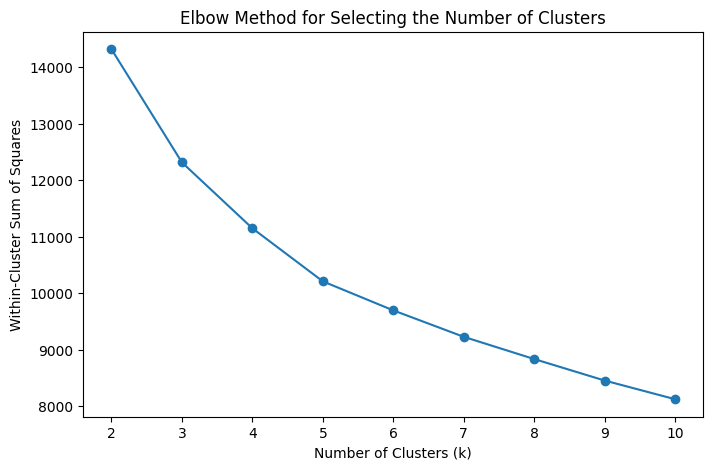

In [17]:
#Data mining

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Selecting the Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.xticks(k_values)
plt.show()

,Number of Clusters,Silhouette Score
0,2,0.270220
1,3,0.213435
2,4,0.206177
3,5,0.176518
4,6,0.167585
5,7,0.156699
6,8,0.164162
7,9,0.162746
8,10,0.163796


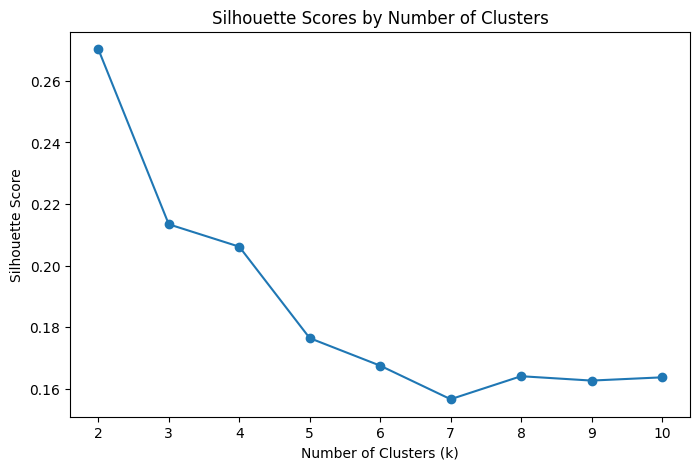

In [18]:
from sklearn.metrics import silhouette_score

silhouette_values = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_values.append(score)

silhouette_results = pd.DataFrame({
    "Number of Clusters": list(k_values),
    "Silhouette Score": silhouette_values
})

display(silhouette_results)

plt.figure(figsize=(8, 5))
plt.plot(
    k_values,
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Scores by Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.show()

In [19]:
candidate_models = {}
candidate_labels = {}

for k in [2, 5]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    candidate_models[k] = model
    candidate_labels[k] = labels

    print(f"\nCluster sizes for k={k}:")
    print(pd.Series(labels).value_counts().sort_index())


Cluster sizes for k=2:
0    1326
1     912
Name: count, dtype: int64

Cluster sizes for k=5:
0    455
1    444
2    570
3    500
4    269
Name: count, dtype: int64


In [20]:
# Customer Profile Comparison

profile_features = [
    "Age",
    "Income",
    "Children_Total",
    "Recency",
    "Total_Spending",
    "Total_Purchases",
    "NumDealsPurchases",
    "NumWebVisitsMonth",
    "Total_Campaign_Accepted"
]

for k in [2, 5]:
    profile_df = df_clean[profile_features].copy()
    profile_df["Cluster"] = candidate_labels[k]

    print(f"\nCustomer profiles for k={k}:")

    display(
        profile_df
        .groupby("Cluster")[profile_features]
        .mean()
        .round(2)
    )


Customer profiles for k=2:


,Age,Income,Children_Total,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebVisitsMonth,Total_Campaign_Accepted
Cluster,,,,,,,,,
0,43.66,38307.35,1.28,48.82,193.55,7.80,2.66,6.49,0.10
1,47.27,72449.07,0.47,49.57,1204.46,19.44,1.84,3.62,0.58



Customer profiles for k=5:


,Age,Income,Children_Total,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebVisitsMonth,Total_Campaign_Accepted
Cluster,,,,,,,,,
0,50.38,42424.75,1.79,50.13,114.16,6.38,2.30,5.94,0.07
1,47.30,70707.39,0.35,49.77,1055.03,18.03,1.25,2.83,0.00
2,36.63,28249.14,0.83,48.34,86.15,5.54,1.75,6.96,0.09
3,47.76,58061.70,1.27,48.06,748.38,17.32,4.62,6.24,0.25
4,45.78,78211.53,0.20,50.02,1529.53,19.85,1.10,3.20,1.71


In [21]:
# K-means model

final_k = 2

final_kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

final_labels = final_kmeans.fit_predict(X_scaled)

df_clustered = df_clean.copy()
df_clustered["Cluster"] = final_labels

print("Final clustering completed.")
print("Number of clusters:", final_k)

print("\nFinal cluster sizes:")
print(df_clustered["Cluster"].value_counts().sort_index())

Final clustering completed.
Number of clusters: 2

Final cluster sizes:
Cluster
0    1326
1     912
Name: count, dtype: int64


In [22]:
#Summarize the clusters

final_profile = (
    df_clustered
    .groupby("Cluster")[profile_features]
    .mean()
    .round(2)
)

display(final_profile)

,Age,Income,Children_Total,Recency,Total_Spending,Total_Purchases,NumDealsPurchases,NumWebVisitsMonth,Total_Campaign_Accepted
Cluster,,,,,,,,,
0,43.66,38307.35,1.28,48.82,193.55,7.80,2.66,6.49,0.10
1,47.27,72449.07,0.47,49.57,1204.46,19.44,1.84,3.62,0.58


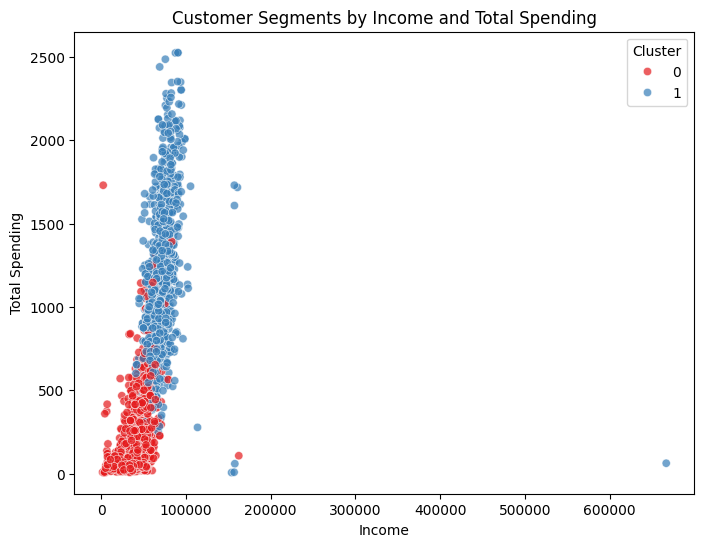

In [24]:
#Cluster Visualization
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df_clustered,
    x="Income",
    y="Total_Spending",
    hue="Cluster",
    palette="Set1",
    alpha=0.7
)

plt.title("Customer Segments by Income and Total Spending")
plt.xlabel("Income")
plt.ylabel("Total Spending")
plt.legend(title="Cluster")
plt.show()

In [25]:
cluster_response = (
    df_clustered
    .groupby("Cluster")["Response"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Customers",
        "sum": "Positive Responses",
        "mean": "Response Rate"
    })
)

cluster_response["Response Rate"] = (
    cluster_response["Response Rate"] * 100
).round(2)

display(cluster_response)

,Customers,Positive Responses,Response Rate
Cluster,,,
0,1326,135,10.18
1,912,199,21.82


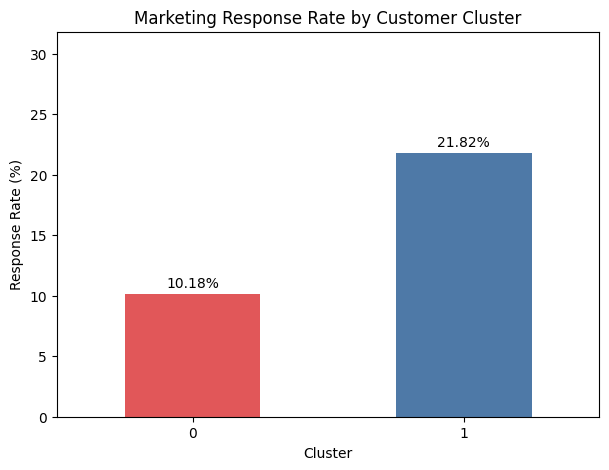

In [26]:
#Visual comparison of the customers

response_rates = cluster_response["Response Rate"]

plt.figure(figsize=(7, 5))
response_rates.plot(
    kind="bar",
    color=["#E15759", "#4E79A7"]
)

plt.title("Marketing Response Rate by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Response Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, max(response_rates) + 10)

for index, value in enumerate(response_rates):
    plt.text(index, value + 0.5, f"{value:.2f}%", ha="center")

plt.show()

In [28]:
#Summary table

final_summary = (
    df_clustered
    .groupby("Cluster")
    .agg(
        Customers=("Cluster", "size"),
        Average_Income=("Income", "mean"),
        Average_Spending=("Total_Spending", "mean"),
        Average_Purchases=("Total_Purchases", "mean"),
        Response_Rate=("Response", "mean")
    )
)

final_summary["Response_Rate"] = (
    final_summary["Response_Rate"] * 100
)

final_summary = final_summary.round(2)

display(final_summary)

,Customers,Average_Income,Average_Spending,Average_Purchases,Response_Rate
Cluster,,,,,
0,1326,38307.35,193.55,7.80,10.18
1,912,72449.07,1204.46,19.44,21.82


In [29]:
#Save the clusters

import joblib

# Save the final K-Means model
joblib.dump(
    final_kmeans,
    "/content/kdd_kmeans_model.joblib"
)

# Save the scaler used during transformation
joblib.dump(
    scaler,
    "/content/kdd_scaler.joblib"
)

# Save customer-level cluster assignments
df_clustered.to_csv(
    "/content/kdd_customer_segments.csv",
    index=False
)

# Save the final segment summary
final_summary.to_csv(
    "/content/kdd_segment_summary.csv"
)

print("KDD artifacts saved successfully.")

KDD artifacts saved successfully.
